# Emotion Classification with RNNs, LSTMs & GRUs

Classifying text into 6 emotions (**sadness, joy, anger, fear, surprise**) by comparing plain recurrent models before building an **Advanced Bidirectional GRU.**

## 1. Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from datasets import load_dataset

## 2. Load Dataset

Load the dair-ai/emotion dataset from Hugging Face. https://huggingface.co/datasets/dair-ai/emotion

In [3]:
emotion_dataset = load_dataset("dair-ai/emotion")

train_text = emotion_dataset['train']['text']
train_labels = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_labels = emotion_dataset['test']['label']

In [5]:
label_names = emotion_dataset['train'].features['label'].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [7]:
df_train = pd.DataFrame({
    'text': train_text,
    'label': [label_names[i] for i in train_labels]
})

df_test = pd.DataFrame({
    'text': test_text,
    'label': [label_names[i] for i in test_labels]
})

df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


## 3. Exploratory Data Analysis (EDA)

Visualize class distribution across 6 emotion labels

<Axes: xlabel='label', ylabel='count'>

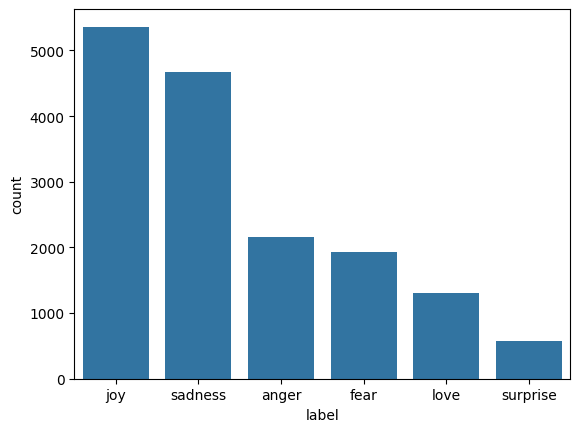

In [9]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

## 4. Data preprocessing using NLP

Tokenize text, pad sequence to max length 50, amd convert labels to numpy arrays

In [15]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
train_padded = pad_sequences(train_sequences, padding='post', truncating='post', maxlen=50)

test_sequences = tokenizer.texts_to_sequences(df_test['text'])
test_padded = pad_sequences(test_sequences, padding='post', truncating='post', maxlen=50)

train_labels = np.array(train_labels)
test_labels = np.array(test_labels)

num_classes = np.unique(train_labels).shape[0]

print(f"Vocabulary size: {len(tokenizer.word_index)}")
print(f"Max Sequence Length: {train_padded.shape[1]}")
print(f"Number of classes: {num_classes}")

Vocabulary size: 15213
Max Sequence Length: 50
Number of classes: 6


## 5. Shared Training Utilities

Compute balanced class weights to handle dataset skew and setup early stopping

In [16]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(train_labels), y=train_labels)
class_weights_dict = dict(enumerate(class_weights))

In [17]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

## 6. Phase 1 - Plain Foundational Models

Train plain (non-bidirectional) Simple RNN, Standard LSTM, and Standard GRU models.

### 6.1 Model 1 - Simple RNN

Plain unrolled Recurrent Neural Network

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    SimpleRNN(units=128, activation='tanh', return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64, activation='tanh', return_sequences=False),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

rnn_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [32]:
rnn_model.fit(
    train_padded, train_labels,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(test_padded, test_labels)
print(f"Test Loss: {rnn_loss}, Test Accuracy: {rnn_accuracy}")

Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 22s 49ms/step - accuracy: 0.1593 - loss: 1.9666 - val_accuracy: 0.1612 - val_loss: 1.7840
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 23s 56ms/step - accuracy: 0.1470 - loss: 1.8256 - val_accuracy: 0.0791 - val_loss: 1.8081
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - accuracy: 0.1438 - loss: 1.7975 - val_accuracy: 0.1184 - val_loss: 1.7858
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.1600 - loss: 1.7869
Test Loss: 1.7868931293487549, Test Accuracy: 0.1599999964237213


### 6.2 Model 2 - Standard LSTM

Plain stacked LSTM network

In [25]:
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    LSTM(units=128, activation='tanh', return_sequences=True),
    Dropout(0.5),
    LSTM(units=64, activation='tanh', return_sequences=False),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

lstm_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [26]:
lstm_model.fit(
    train_padded, train_labels,
    validation_data=(test_padded, test_labels),
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(test_padded, test_labels)
print(f"Test Loss: {lstm_loss}, Test Accuracy: {lstm_accuracy}")

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 137ms/step - accuracy: 0.1573 - loss: 1.7942 - val_accuracy: 0.2910 - val_loss: 1.7869
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 76s 153ms/step - accuracy: 0.1499 - loss: 1.7938 - val_accuracy: 0.3460 - val_loss: 1.7824
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 78s 155ms/step - accuracy: 0.1356 - loss: 1.7922 - val_accuracy: 0.1170 - val_loss: 1.7905
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.2910 - loss: 1.7869
Test Loss: 1.7869306802749634, Test Accuracy: 0.29100000858306885


### 6.3 Model 3 - Standard GRU

Plain stacked Gated Recurrent Unit network

In [27]:
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    GRU(units=128, activation='tanh', return_sequences=True),
    Dropout(0.5),
    GRU(units=64, activation='tanh', return_sequences=False),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

gru_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [29]:
gru_model.fit(
    train_padded, train_labels,
    validation_data=(test_padded, test_labels),
    epochs=10,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(test_padded, test_labels)
print(f"Test Loss: {gru_loss}, Test Accuracy: {gru_accuracy}")

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - accuracy: 0.1392 - loss: 1.7940 - val_accuracy: 0.1165 - val_loss: 1.7920
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 108ms/step - accuracy: 0.1655 - loss: 1.7930 - val_accuracy: 0.3220 - val_loss: 1.7858
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 92s 128ms/step - accuracy: 0.1616 - loss: 1.7892 - val_accuracy: 0.2505 - val_loss: 1.7750
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.1165 - loss: 1.7920
Test Loss: 1.791960597038269, Test Accuracy: 0.11649999767541885


### 6.4 Phase 1 Ranking & Selection

Rank foundational models to pick the best base cell for phase 2.

In [33]:
result_df = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],
    'Loss': [rnn_loss, lstm_loss, gru_loss],
    'Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
})

result_df

,Model,Loss,Accuracy
0,RNN,1.786893,0.1600
1,LSTM,1.786931,0.2910
2,GRU,1.791961,0.1165


## 7. Phase 2 - Advanced Bidirectional GRU

Enhance GRU with Bidirectional layers, 300D embeddings, and 0.5 dropout regularization

### 7.1 Model 4 - Advanced Stacked Bidirectional GRU

In [38]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(units=128, activation='tanh', return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64, activation='tanh', return_sequences=False)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

BiGRU.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
BiGRU.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_8 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [39]:
BiGRU.fit(
    train_padded, train_labels,
    validation_data=(test_padded, test_labels),
    epochs=10,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(test_padded, test_labels)
print(f"Test Loss: {BiGRU_loss}, Test Accuracy: {BiGRU_accuracy}")

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 155s 294ms/step - accuracy: 0.5265 - loss: 1.0871 - val_accuracy: 0.8775 - val_loss: 0.4378
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 146s 291ms/step - accuracy: 0.9082 - loss: 0.2724 - val_accuracy: 0.9090 - val_loss: 0.2787
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 242s 371ms/step - accuracy: 0.9377 - loss: 0.1733 - val_accuracy: 0.9240 - val_loss: 0.2086
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 168s 336ms/step - accuracy: 0.9589 - loss: 0.1164 - val_accuracy: 0.9160 - val_loss: 0.2425
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 167s 333ms/step - accuracy: 0.9704 - loss: 0.0805 - val_accuracy: 0.9125 - val_loss: 0.2909
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 146s 291ms/step - accuracy: 0.9747 - loss: 0.0712 - val_accuracy: 0.9205 - val_loss: 0.3235
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.9240 - loss: 0.2086
Test Loss: 0.20861074328422546, Test Accuracy: 0.9240000247955322


## 8. Overall Evaluation & Bias Analysis

Consolidate test metrics, plot raw & normalized confusion matrices, and analyze bias

### 8.1 Final Model Confusion Matrices (Raw Counts & Normalized %)

In [41]:
models = ['RNN', 'LSTM', 'GRU', 'BiGRU']
losses = [rnn_loss, lstm_loss, gru_loss, BiGRU_loss]
accuracies = [rnn_accuracy, lstm_accuracy, gru_accuracy, BiGRU_accuracy]

results_df = pd.DataFrame({
    'Model': models,
    'Test Loss': losses,
    'Test Accuracy': accuracies
})

results_df

,Model,Test Loss,Test Accuracy
0,RNN,1.786893,0.1600
1,LSTM,1.786931,0.2910
2,GRU,1.791961,0.1165
3,BiGRU,0.208611,0.9240


63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 104ms/step


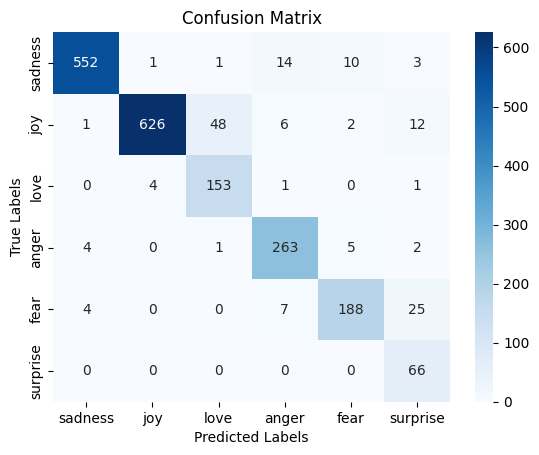

In [43]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = BiGRU.predict(test_padded)
BiGRU_predictions = np.argmax(BiGRU_predictions, axis=1)

sns.heatmap(confusion_matrix(test_labels, BiGRU_predictions), annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

cm = confusion_matrix(test_labels, BiGRU_predictions)

## 9. Final Predictions

Test the winning model on unseen sample sentences

In [44]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


 ## 10. Save Model & Tokenizer

 Export trained model and tokenizer artifacts for API deployment

In [46]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

BiGRU.save(os.path.join(model_dir, 'BiGRU_model.keras'))

with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as f:
    pickle.dump(tokenizer, f)